# Gaia-4 b: radial velocities and Gaia DR4 epoch astrometry

We first fit the published radial velocities of Gaia-4, then add the Gaia DR4
prerelease along-scan astrometry. The RV posterior supplies starting positions
for the joint sampler.

The radial velocities are from [Stefánsson et al. (2025), Table 5](https://doi.org/10.3847/1538-3881/ada9e1).
Both datasets are bundled in `orbitize/example_data`.

**Gaia data credit: ESA/Gaia/DPAC.** See the [ESA DR4 prerelease](https://www.cosmos.esa.int/web/gaia/dr4-prerelease)
and the [bundled data README](../../orbitize/example_data/gaia_dr4_eas_README.md).

In [2]:
from copy import copy
from pathlib import Path
from time import perf_counter
import sys
from astropy.time import Time

repo_root = Path("../..").resolve()
sys.path.insert(0, str(repo_root))

import corner
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u

import orbitize
from orbitize.basis import tp_to_tau
from orbitize import gaia, plot, priors, read_input, sampler, system

np.random.seed(42)
rng = np.random.default_rng(42)

source_id = 1457486023639239296
ref_epoch_mjd = 57936.375  # J2017.5, MJD(TCB)

stellar_mass = 0.644      # Msun
stellar_mass_err = 0.024  # Msun, symmetric approximation

num_temps = 10
num_walkers = 128
num_threads = 10
burn_steps = 100
num_steps = 500
thin = 1

## 1. Read and inspect the RVs

The CSV contains 23 RVs: 10 HPF, 8 NEID and 5 FIES. Velocities and formal
errors are in km/s. Published BJD(TDB) timestamps were converted to
MJD(TCB) to match EAS, with the original timestamps retained in the CSV.
We will fit a separate offset and jitter for each instrument.

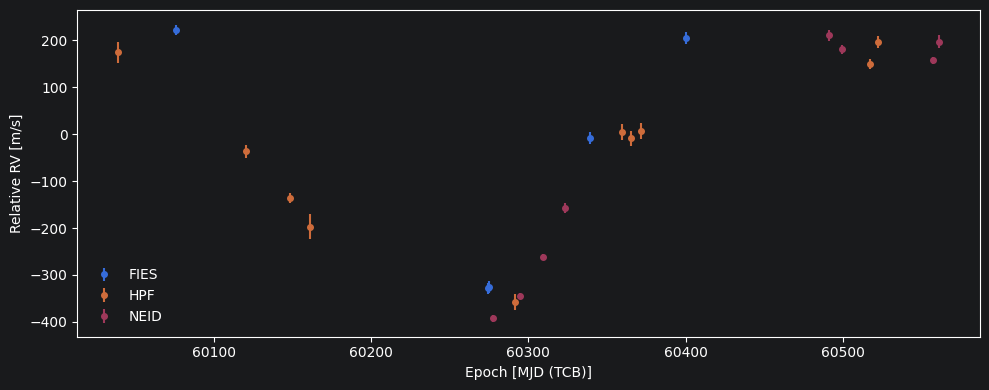

In [3]:
rv_path = Path(orbitize.DATADIR) / "gaia4_rv_stefansson2025.csv"
rv_data = read_input.read_file(rv_path)

fig, ax = plt.subplots(figsize=(10, 4))
for instrument in np.unique(rv_data["instrument"]):
    rv = rv_data[rv_data["instrument"] == instrument]
    ax.errorbar(
        rv["epoch"], 1000 * rv["quant1"],
        yerr=1000 * rv["quant1_err"],
        fmt="o", ms=4, label=instrument,
    )

ax.set(xlabel="Epoch [MJD (TCB)]", ylabel="Relative RV [m/s]")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 2. RV system and shared priors

Use **SemiAmp** for both fits: it samples period $P$ and stellar RV amplitude
$K$, deriving relative semimajor axis and companion mass through the basis. The stellar mass estimate is from the paper's SED/
isochrone analysis, which used Gaia distance. See [Table 1 and Section 3](https://arxiv.org/html/2410.05654v1#S3).

In [4]:
def set_shared_priors(fit_system):
    idx = fit_system.param_idx
    fit_priors = fit_system.sys_priors

    for name, prior in {
        "per1": priors.LogUniformPrior(0.1, 10.0),
        "ecc1": priors.UniformPrior(0.0, 0.95),
        "K1": priors.LogUniformPrior(0.001, 2.0),
        "plx": priors.UniformPrior(5.0, 25.0),
    }.items():
        fit_priors[idx[name]] = prior

    for instrument in fit_system.rv_instruments:
        fit_priors[idx[f"gamma_{instrument}"]] = priors.UniformPrior(-2.0, 2.0)
        fit_priors[idx[f"sigma_{instrument}"]] = priors.LogUniformPrior(1e-4, 0.1)


rv_system = system.System(
    1, rv_data, stellar_mass, 13.6,
    mass_err=stellar_mass_err,
    plx_err=1.0,
    fit_secondary_mass=True,
    tau_ref_epoch=ref_epoch_mjd,
    fitting_basis="SemiAmp",
)
set_shared_priors(rv_system)
rv_idx = rv_system.param_idx

## 3. Fit the RVs

Let's fit for the RV data by itself first, then plot its results. We're starting near the solution from the paper, but the priors remain broad.

In [14]:
rv_mcmc = sampler.MCMC(
    rv_system, num_temps=num_temps, num_walkers=num_walkers, num_threads=num_threads
)
pos = rv_mcmc.curr_pos
cols = rv_mcmc.sampled_param_idx
shape = pos.shape[:-1]

period = rng.normal(513.0, 10.0, size=shape) / 365.25
tp_mjd = Time(2460244.5, format="jd", scale="tdb").tcb.mjd
pos[..., cols["per1"]] = period
pos[..., cols["tau1"]] = tp_to_tau(
    rng.normal(tp_mjd, 5.0, size=shape), rv_system.tau_ref_epoch, period
)
pos[..., cols["aop1"]] = np.deg2rad(
    rng.normal(181.8 + 180, 3.0, size=shape) % 360
)

for name, center, spread in (
    ("ecc1", 0.263, 0.02),
    ("K1", 0.355, 0.015),
    ("gamma_HPF", -0.074, 0.01),
    ("gamma_NEID", -0.057, 0.01),
    ("gamma_FIES", 0.042, 0.01),
):
    pos[..., cols[name]] = rng.normal(center, spread, size=shape)

rv_mcmc.check_prior_support()

In [15]:
start = perf_counter()
rv_run = rv_mcmc.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
rv_post = rv_mcmc.results.post

print(f"RV run took {(perf_counter() - start) / 60:.1f} minutes")
print(f"Cold-chain acceptance: {rv_run.acceptance_fraction[0].mean():.3f}")

Starting Burn in


/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: Runt

100/100 steps of burn-in complete
Burn in complete. Sampling posterior now.
500/500 steps completed
Run complete
RV run took 1.4 minutes
Cold-chain acceptance: 0.147


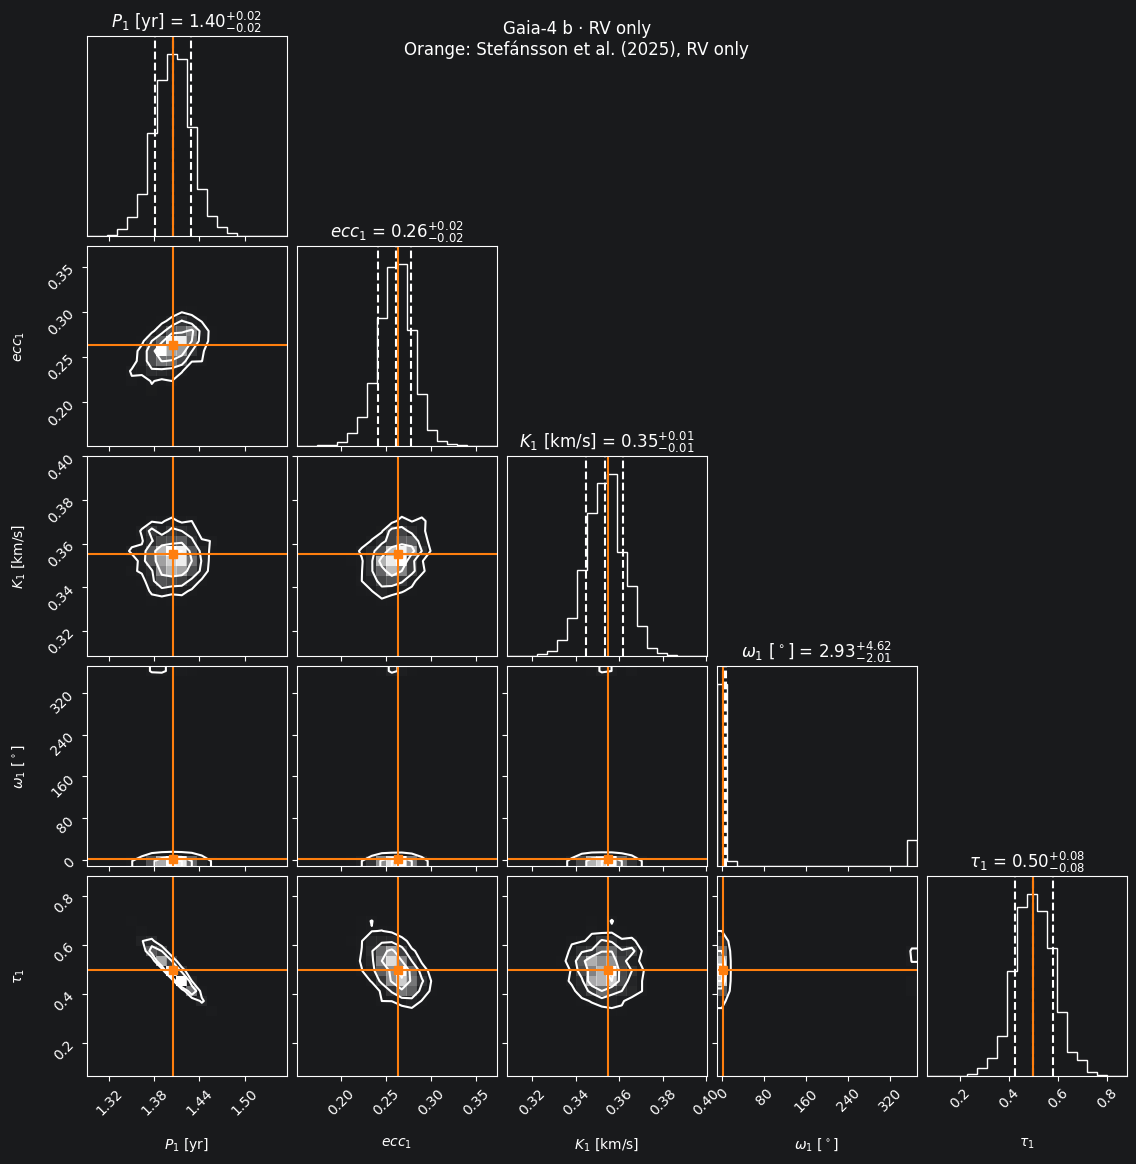

In [16]:
from orbitize.basis import tp_to_tau

rv_results = rv_mcmc.results
rv_params = ["per1", "ecc1", "K1", "aop1", "tau1"]

period_yr = 513.0 / 365.25
tp_mjd = Time(2460244.5, format="jd", scale="tdb").tcb.mjd
published_rv = [
    period_yr, 0.263, 0.355, (181.8 + 180) % 360,
    tp_to_tau(tp_mjd, rv_system.tau_ref_epoch, period_yr),
]

samples = rv_results.post[:, [rv_results.param_idx[name] for name in rv_params]]
samples[:, 3] = np.rad2deg(samples[:, 3])
lo = np.minimum(samples.min(axis=0), published_rv)
hi = np.maximum(samples.max(axis=0), published_rv)
pad = 0.03 * (hi - lo)

rv_corner = plot.plot_corner(
    rv_results,
    param_list=rv_params,
    truths=published_rv,
    truth_color="tab:orange",
    range=list(zip(lo - pad, hi + pad)),
    plot_priors=False,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
)
rv_corner.suptitle("Gaia-4 b · RV only\nOrange: Stefánsson et al. (2025), RV only")
plt.show()

## 4. Read and reduce the EAS astrometry

Bootstrap **within each transit once**, with 500
resamples. Use the original CCD median as the transit position and the
bootstrap standard deviation of the median as its uncertainty, with floor
$\mathrm{median}(\sigma_{\rm IPD})/\sqrt{N_{\rm CCD}}$.

This source has 824 selected CCD measurements in 93 transits. The reduction
uses the mean CCD epoch and first CCD's scan angle/parallax factor.

In [17]:
xml_path = Path(orbitize.DATADIR) / "GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml"
ccd_data = read_input.from_dl2(xml_path, source_id)
data = read_input.combine_transits(ccd_data, rng=rng)

print(f"{len(ccd_data)} CCD measurements → {len(data)} transits")
data[:5]

824 CCD measurements → 93 transits


source_id,transit_id,obs_time_tcb,centroid_pos_al,centroid_pos_error_al,parallax_factor_al,scan_pos_angle,field_of_view,n_ccd,parallax_factor_ac
,,d,mas,mas,,rad,,,
int64,int64,float64,float64,float64,float32,float64,int64,int64,float32
1457486023639239296,24595081341060059,57038.63423206328,128.97026560877987,0.03311802667299798,0.6835317,2.698211981304289,1,8,0.7007018
1457486023639239296,24599173634106091,57038.7082925621,128.89253382127117,0.06404046832254703,0.68234825,2.6988676291118177,2,9,0.70163137
1457486023639239296,25756167184339289,57059.63340424154,-97.48322333940874,0.06448290111716617,-0.5619547,-2.404402218448475,1,9,0.7034467
1457486023639239296,31071350778787318,57155.75682197189,70.04375307433236,0.053874148027575966,0.4003003,0.6338771007964691,1,9,0.7203316
1457486023639239296,31075443107095903,57155.83083274437,70.60863370167266,0.021922124770253033,0.3970468,0.6374634557664154,2,9,0.7226604


## 5. Joint system

The RV likelihood receives the original RV table once. Gaia receives the
93 row reduced table. The shared priors are exactly
the same as in the RV fit. Additional terms are a Gaia jitter with log-uniform
prior 0.0001–10 mas and the basis's four freely sampled linear parameters:
position offsets and proper motion, each uniform on −10,000–10,000
(mas for offsets, mas/yr for proper motions).


In [18]:
dr4 = gaia.DR4LogProb(
    source_id,
    data,
    ref_epoch_mjd=ref_epoch_mjd,
    jitter_prior=priors.LogUniformPrior(1e-4, 10.0),
)

my_sys = system.System(
    1, rv_data, stellar_mass, 13.6,
    mass_err=stellar_mass_err,
    plx_err=1.0,
    fit_secondary_mass=True,
    gaia=dr4,
    tau_ref_epoch=ref_epoch_mjd,
    fitting_basis="SemiAmp",
)

set_shared_priors(my_sys)
idx = my_sys.param_idx

## 6. Initialize the joint sampler

We start the walkers from RV posterior draws within 2 log-likelihood units
of the best RV fit. Inclination, longitude of the ascending node (LAN),
and Gaia jitter start from their priors.

For each starting orbit, we use the Gaia data to estimate two position
offsets and two proper-motion components. The joint MCMC samples these
four parameters alongside the orbit.

In [26]:
mcmc = sampler.MCMC(
    my_sys, num_temps=num_temps, num_walkers=num_walkers, num_threads=num_threads
)
sampled_idx = mcmc.sampled_param_idx
positions = mcmc.curr_pos.reshape(-1, mcmc.num_params)

rv_results = rv_mcmc.results
rv_logl = np.asarray(rv_results.lnlike)
finite = np.isfinite(rv_logl)
if not finite.any():
    raise ValueError("The RV fit has no finite log-likelihood draws.")

eligible = np.flatnonzero(finite & (rv_logl >= rv_logl[finite].max() - 2.0))
draws = rng.choice(eligible, size=len(positions), replace=True)
shared = [
    name for name in sampled_idx
    if name in rv_idx and name not in ("inc1", "pan1")
]
positions[:, [sampled_idx[name] for name in shared]] = rv_results.post[draws][
    :, [rv_idx[name] for name in shared]
]

full_positions = mcmc._fill_in_fixed_params(positions)
ra, dec, _, _ = my_sys.compute_all_orbits(
    full_positions.T, epochs=dr4.epochs_mjd, params_basis="fitting"
)

linear_columns = [
    sampled_idx[name] for name in ("alpha0", "delta0", "pm_ra", "pm_dec")
]
for i, params in enumerate(full_positions):
    positions[i, linear_columns] = dr4.guess_initial_astrometry(
        ra[:, 0, i], dec[:, 0, i], params[idx["plx"]], params[idx["dr4_jitter"]]
    )

mcmc.curr_pos = positions.reshape(mcmc.curr_pos.shape)
mcmc.check_prior_support()

In [27]:
start = perf_counter()
run = mcmc.run_sampler(
    mcmc.num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
post = mcmc.results.post

print(f"Joint run took {(perf_counter() - start) / 60:.1f} minutes")
print(f"Cold-chain acceptance: {run.acceptance_fraction[0].mean():.3f}")

Starting Burn in


/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/private/tmp/orbitize-463-stack/orbitize/priors.py:566: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/private/tmp/orbitize-463-stack/orbitize/priors.py:417: RuntimeWarni

100/100 steps of burn-in complete
Burn in complete. Sampling posterior now.
500/500 steps completed
Run complete
Joint run took 3.2 minutes
Cold-chain acceptance: 0.162


## 7. Joint posterior

The corner plot shows the parameters
inferred from the joint RV and Gaia DR4 fit. Orange lines mark the published
orbital values from the Gaia DR3 + RV fit in
[Stefánsson et al. (2025), Table 2](https://doi.org/10.3847/1538-3881/ada9e1).

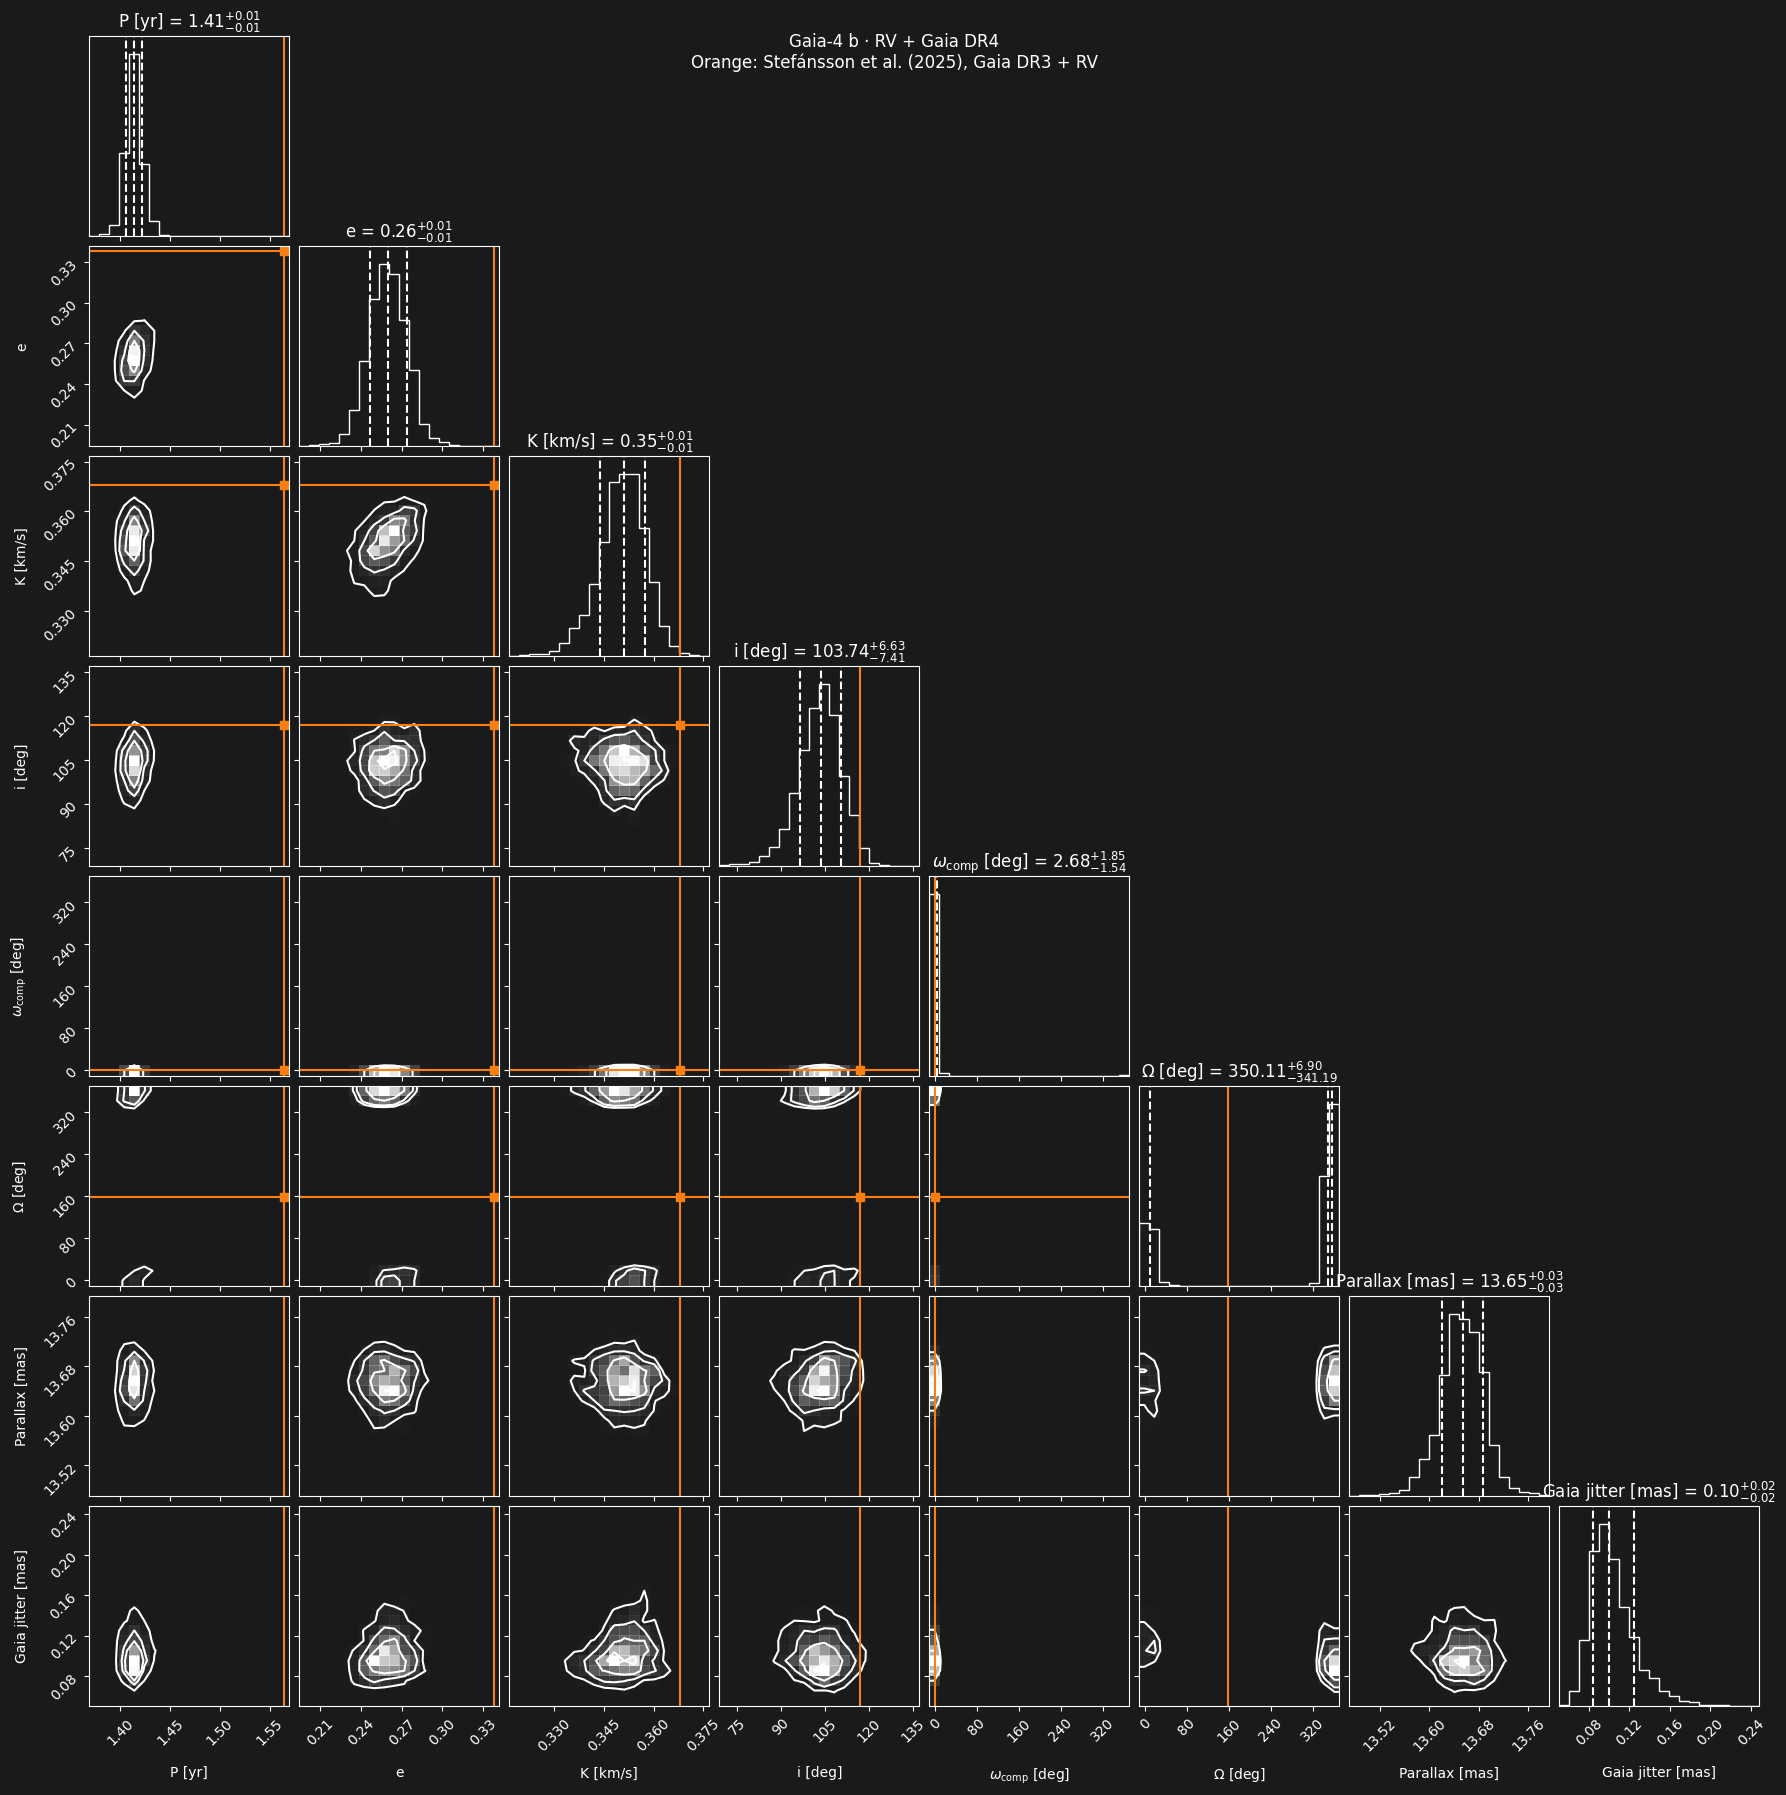

In [28]:
joint_results = mcmc.results
params = ["per1", "ecc1", "K1", "inc1", "aop1", "pan1", "plx", "dr4_jitter"]
published_joint = [
    571.3 / 365.25, 0.338, 0.368, 116.9,
    (180.3 + 180) % 360, 158.6, None, None,
]

samples = joint_results.post[:, [joint_results.param_idx[name] for name in params]]
samples[:, 3:6] = np.rad2deg(samples[:, 3:6])
reference = np.asarray(published_joint, dtype=float)
lo = np.fmin(samples.min(axis=0), reference)
hi = np.fmax(samples.max(axis=0), reference)
pad = 0.03 * (hi - lo)

fig = plot.plot_corner(
    joint_results,
    param_list=params,
    labels=[
        "P [yr]", "e", "K [km/s]", "i [deg]",
        r"$\omega_{\rm comp}$ [deg]", r"$\Omega$ [deg]",
        "Parallax [mas]", "Gaia jitter [mas]",
    ],
    truths=published_joint,
    truth_color="tab:orange",
    range=list(zip(lo - pad, hi + pad)),
    plot_priors=False,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
)
fig.suptitle("Gaia-4 b · RV + Gaia DR4\nOrange: Stefánsson et al. (2025), Gaia DR3 + RV")
plt.show()

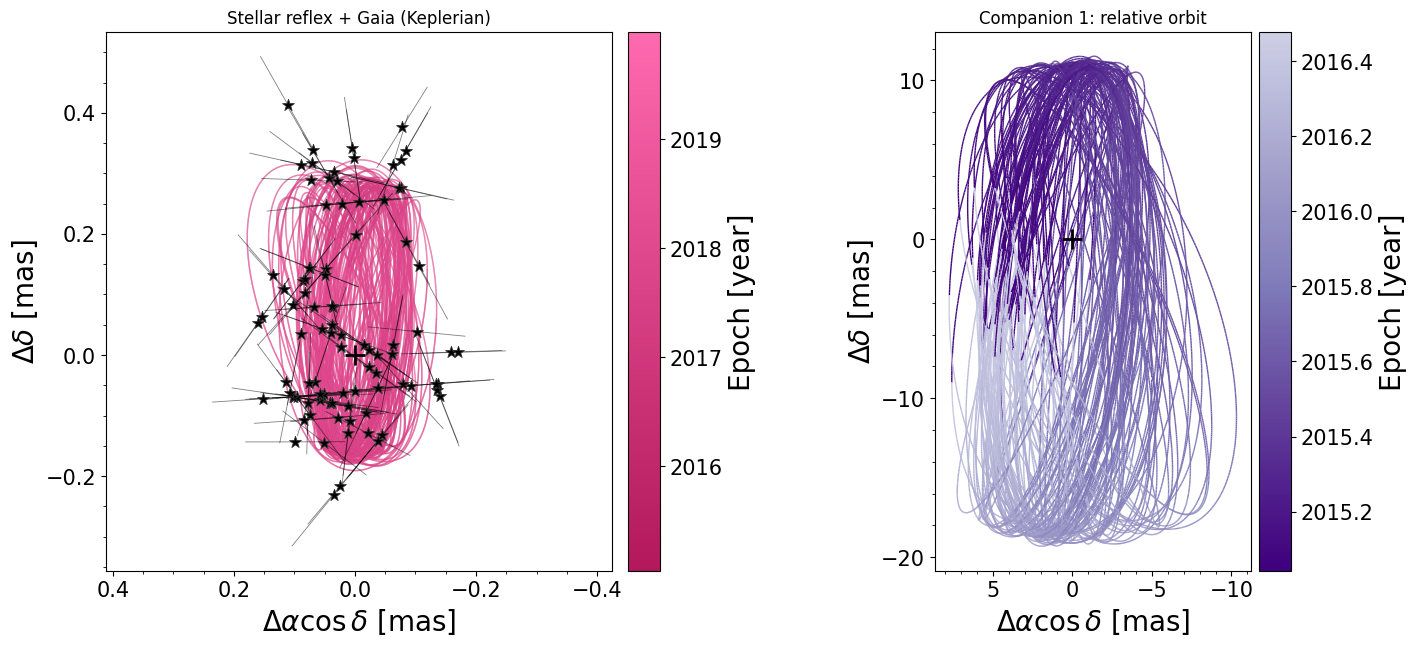

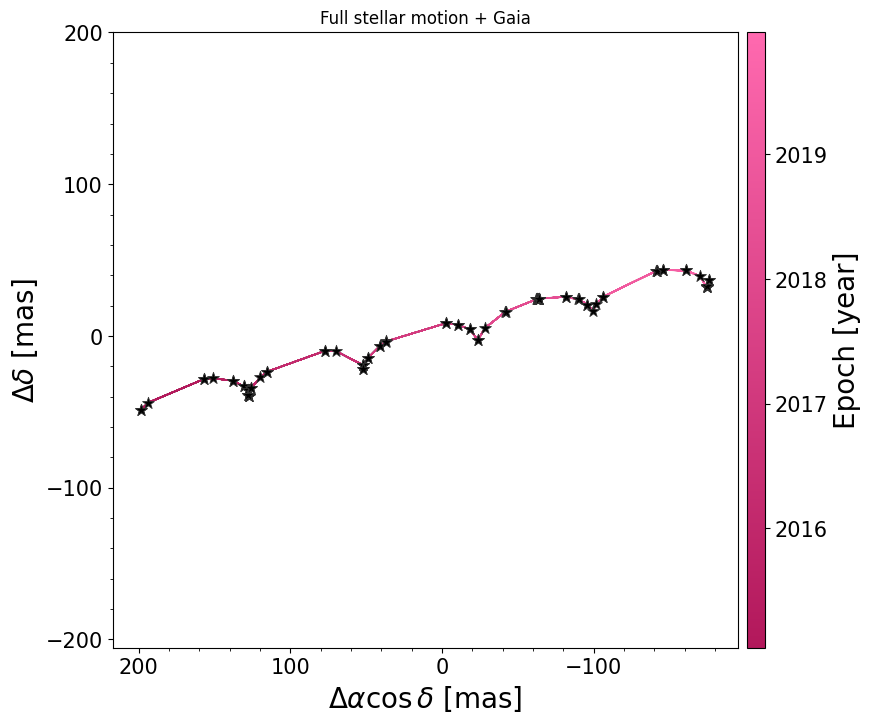

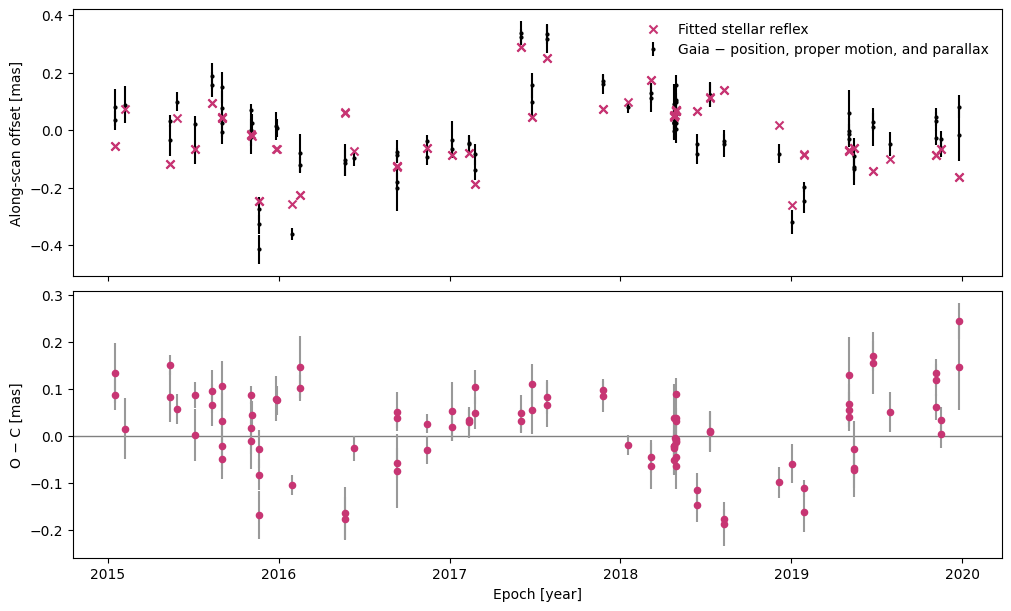

In [31]:
joint_results = mcmc.results

joint_results.plot_dr4_orbit(
    mcmc.system, mode="keplerian", include_planet=True, include_jitter=True
)
joint_results.plot_dr4_orbit(
    mcmc.system, mode="full_motion", include_jitter=True
)
plot.Plotter.plot_dr4_al_residuals(joint_results)

plt.show()

## 8. Save the joint result

Save the RV+DR4 joint fit

In [33]:
mcmc.results.save_results("Gaia_DR4_Gaia4_results.hdf5")